# AnalystLab Africa – Experience Lab Internship, Week 3
## Track B (Data Science): Healthcare Operations – Statistical Investigation & Insight Discovery

**Research question:** *How do total claim costs vary across encounter classes, and is encounter duration (and the presence of procedures) associated with recorded claim cost?*

**Dataset:** AnalystLab Africa healthcare pack – `encounters.csv`, `procedures.csv`, `patients.csv`, `payers.csv`, `organizations.csv`, `data_dictionary.csv`


| # | Section | Brief requirement covered |
|---|---|---|
| 1 | Business problem | General Task 1 |
| 2 | Research question | Track B Task 1 |
| 3 | Success criteria | General Task 3 |
| 4–7 | Set-up, data inspection, data quality, relationships, dates | General Task 2 / Deliverable 2 |
| 8 | Data preparation | Track B Task 2 |
| 9–12 | Exploratory data analysis (10 figures) | Track B Task 2 / Deliverable 3 |
| 13–15 | Hypothesis tests H1, H2, H3 | Track B Task 3 |
| 16 | Limitations (missing data, group sizes, repeats, confounding, causation) | Track B Task 4 |
| 17 | Validation scorecard | General Tasks 3–4 |
| 18–19 | Analytical report, findings and recommendations | Track B Task 5 / Deliverables 4–5 |
| 20 | Reproduction instructions, privacy note, references | Deliverable 6 / General Task 4 |

## 1. Understanding the business problem

**The problem.** The hospital wants to understand what drives the money recorded on its encounters. Claim costs are extremely uneven (a typical claim is a few hundred dollars, a few are hundreds of thousands), so averages alone can mislead planners.

**Why it matters.** Budgeting, payer negotiation, capacity planning and the setting of data-capture standards all depend on knowing *which kinds of encounters* are expensive, whether *longer encounters* cost more, and whether *procedures* explain high claims.

**Intended user.** A hospital operations / finance analyst or manager who must decide where to look first when reviewing cost and data quality.

**Decisions this work can support.**
- Which encounter classes deserve cost-control or coding review first.
- Whether encounter duration is a trustworthy cost indicator, or whether its capture needs fixing.
- Whether procedure-related billing should be the focus of cost monitoring.

**Limitations of the evidence (detailed in section 16).** One organisation only; costs are *recorded* amounts, not clinical value; encounters are repeated records of the same 974 patients; duration is recorded coarsely; no currency is stated in the data dictionary (US dollars are assumed because all payers are US-based). Nothing here is a clinical claim or treatment recommendation.

## 2. Research question, relevance and variables

**Primary research question.** How do `TOTAL_CLAIM_COST` values vary across encounter classes, and is encounter duration associated with recorded claim cost (after allowing for encounter class)?

**Relevance.** Directly supports cost-driver analysis for hospital operations and tests whether duration – a commonly used operational measure – tells us anything about cost.

**Variables required**

| Variable | Source | Role |
|---|---|---|
| `TOTAL_CLAIM_COST` | encounters | Outcome (continuous, heavily skewed, ≥ 0) |
| `ENCOUNTERCLASS` | encounters | Grouping factor (6 categories) |
| `START`, `STOP` → `duration_hours` | encounters | Explanatory variable (derived) |
| `Id`, `ENCOUNTER`, `BASE_COST` → `n_procedures`, `has_procedure` | procedures | Explanatory variable (derived) |
| `PAYER_COVERAGE`, `PATIENT` | encounters | Data-quality and independence checks |

**Hypotheses (tested in sections 13–15)**

| | Null (H0) | Alternative (H1) | Method |
|---|---|---|---|
| **H1** | The distribution of `TOTAL_CLAIM_COST` is the same in all six encounter classes | At least one class tends to have higher or lower costs | Kruskal–Wallis, Bonferroni-adjusted Mann–Whitney post-hoc, Cliff's delta |
| **H2** | No monotonic association between duration and `TOTAL_CLAIM_COST` (ρ = 0) | ρ ≠ 0 | Spearman correlation, bootstrap CI, within-class and partial (class-adjusted) versions |
| **H3** | Cost distributions are the same with and without a recorded procedure | They differ | Mann–Whitney U, Cliff's delta, stratified by class |

## 3. Success criteria (measurable)

The work is judged successful only if **all** of the following are met (scored automatically in section 17):

1. **Independent reconciliation:** the Kruskal–Wallis H statistic recomputed manually from ranks equals the SciPy result.
2. **Totals reconcile:** class record counts and cost totals equal the raw-file counts and totals.
3. **Independent medians:** per-class medians from pandas equal those from a pure-NumPy calculation.
4. **Uncertainty is reported:** every class median has a bootstrap 95 % CI that brackets the sample median.
5. **Robustness:** conclusions survive a sensitivity analysis using one random encounter per patient (independent observations).
6. **No silent data changes:** no rows dropped and no cost values altered or imputed.

## 4. Set-up and libraries

In [1]:
import os  # operating-system helpers (folders, file paths)
import itertools  # builds all pairs of encounter classes for post-hoc tests
import warnings  # lets us silence harmless warnings
import numpy as np  # fast numerical arrays and maths
import pandas as pd  # data tables (DataFrames)
import matplotlib.pyplot as plt  # base plotting library
import seaborn as sns  # statistical plotting on top of matplotlib
from scipy import stats  # statistical tests (Kruskal-Wallis, Spearman, Mann-Whitney, ...)

warnings.filterwarnings("ignore")  # hide non-critical warnings to keep output readable
sns.set_theme(style="whitegrid", context="notebook")  # consistent clean plot style
pd.set_option("display.max_columns", 50)  # show up to 50 columns when printing tables
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")  # format floats with 3 decimals
RNG = np.random.default_rng(42)  # fixed random seed so every re-run gives identical results
OUTPUT_DIR = "outputs"  # folder where tables and figures are saved
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")  # sub-folder for saved charts
os.makedirs(FIG_DIR, exist_ok=True)  # create the folders if they do not exist yet
print("Libraries loaded. Outputs will be saved in:", os.path.abspath(OUTPUT_DIR))  # confirm set-up

Libraries loaded. Outputs will be saved in: C:\Users\Tarfa_Jr\outputs


### What this cell does
Loads the libraries, fixes the random seed (`42`) so results are identical on every run, and creates an `outputs/` folder where all tables and figures are saved automatically (these become your evidence files for submission).

## 5. Load the datasets (paste your file paths here) and inspect sizes
**General Task 2 – tables, fields, record and column counts.**

In [2]:
encounters = pd.read_csv(r"encounters.csv", encoding="utf-8-sig")  # one row per encounter
patients = pd.read_csv(r"patients.csv", encoding="utf-8-sig")  # one row per patient (contains personal data!)
procedures = pd.read_csv(r"procedures.csv", encoding="utf-8-sig")  # one row per procedure performed
payers = pd.read_csv(r"payers.csv", encoding="utf-8-sig")  # one row per insurance payer
organizations = pd.read_csv(r"organizations.csv", encoding="utf-8-sig")  # the hospital(s) in the data
data_dictionary = pd.read_csv(r"data_dictionary.csv", encoding="utf-8-sig")  # official field definitions


tables = {  # collect every data table in one dictionary so we can loop over them
    "encounters": encounters,  # encounter-level data (main analysis table)
    "patients": patients,  # patient demographics
    "procedures": procedures,  # procedure line items
    "payers": payers,  # payer reference list
    "organizations": organizations,  # organisation reference list
}  # end of dictionary
for name, df in tables.items():  # loop through each table
    print(f"{name:<14} rows = {df.shape[0]:>7,}   columns = {df.shape[1]}")  # print the record and column counts

encounters     rows =  27,891   columns = 14
patients       rows =     974   columns = 20
procedures     rows =  47,701   columns = 9
payers         rows =      10   columns = 7
organizations  rows =       1   columns = 8


### Result and interpretation
All six files loaded. **Selected tables and sizes:**

| Table | Records | Columns | Used for |
|---|---|---|---|
| encounters | 27,891 | 14 | Main analysis |
| procedures | 47,701 | 9 | Procedure count/cost per encounter |
| patients | 974 | 20 | Integrity and date checks only (no personal data displayed) |
| payers | 10 | 7 | Payer names |
| organizations | 1 | 8 | Context – the data represents a **single hospital** (Massachusetts General Hospital) |
| data_dictionary | 64 rows (59 field definitions) | 3 | Field definitions |

**Privacy:** `patients.csv` contains names and addresses. This notebook never prints or plots them; only the ID and date columns are used.

## 6. Data-quality assessment (missing values, duplicates, data types)

In [3]:
def quality_summary(df, name, key_cols=None):  # build a one-row data-quality summary for a table
    missing_cells = int(df.isna().sum().sum())  # total number of empty cells in the table
    cols_with_missing = int((df.isna().sum() > 0).sum())  # number of columns that have at least one empty cell
    full_dups = int(df.duplicated().sum())  # rows that are exact copies of an earlier row
    key_dups = int(df.duplicated(subset=key_cols).sum()) if key_cols else np.nan  # repeated primary-key values
    return pd.Series({  # return the summary as a labelled series
        "table": name,  # table name
        "rows": len(df),  # number of records
        "columns": df.shape[1],  # number of columns
        "missing_cells": missing_cells,  # total missing cells
        "cols_with_missing": cols_with_missing,  # columns affected by missing values
        "exact_duplicate_rows": full_dups,  # fully duplicated rows
        "duplicate_primary_keys": key_dups,  # duplicated primary keys (NaN if no key defined)
    })  # end of series

dq_summary = pd.DataFrame([  # stack the per-table summaries into one table
    quality_summary(encounters, "encounters", ["Id"]),  # encounters: key is Id
    quality_summary(patients, "patients", ["Id"]),  # patients: key is Id
    quality_summary(procedures, "procedures", None),  # procedures: no primary key supplied
    quality_summary(payers, "payers", ["Id"]),  # payers: key is Id
    quality_summary(organizations, "organizations", ["Id"]),  # organisations: key is Id
]).set_index("table")  # use table name as the index
display(dq_summary)  # show the summary table

print("\nColumns with missing values (count and % of rows):")  # heading for the detailed view
for name, df in tables.items():  # loop through each table
    miss = df.isna().sum()  # missing count per column
    miss = miss[miss > 0]  # keep only columns that actually have missing values
    for col, n_missing in miss.items():  # loop through the affected columns
        print(f"  {name}.{col}: {n_missing:,} missing ({n_missing / len(df):.1%})")  # print count and percentage

print("\nData types in encounters.csv and procedures.csv:")  # heading for dtype check
print(encounters.dtypes.astype(str).to_string())  # list encounter column types
print(procedures.dtypes.astype(str).to_string())  # list procedure column types

,rows,columns,missing_cells,cols_with_missing,exact_duplicate_rows,duplicate_primary_keys
table,,,,,,
encounters,27891,14,39082,2,0,0.000
patients,974,20,2504,5,0,0.000
procedures,47701,9,73890,2,0,NaN
payers,10,7,5,5,0,0.000
organizations,1,8,0,0,0,0.000



Columns with missing values (count and % of rows):
  encounters.REASONCODE: 19,541 missing (70.1%)
  encounters.REASONDESCRIPTION: 19,541 missing (70.1%)
  patients.DEATHDATE: 820 missing (84.2%)
  patients.SUFFIX: 953 missing (97.8%)
  patients.MAIDEN: 588 missing (60.4%)
  patients.MARITAL: 1 missing (0.1%)
  patients.ZIP: 142 missing (14.6%)
  procedures.REASONCODE: 36,945 missing (77.5%)
  procedures.REASONDESCRIPTION: 36,945 missing (77.5%)
  payers.ADDRESS: 1 missing (10.0%)
  payers.CITY: 1 missing (10.0%)
  payers.STATE_HEADQUARTERED: 1 missing (10.0%)
  payers.ZIP: 1 missing (10.0%)
  payers.PHONE: 1 missing (10.0%)

Data types in encounters.csv and procedures.csv:
Id                      object
START                   object
STOP                    object
PATIENT                 object
ORGANIZATION            object
PAYER                   object
ENCOUNTERCLASS          object
CODE                     int64
DESCRIPTION             object
BASE_ENCOUNTER_COST    float64
TOTAL_

### Data-quality findings (Deliverable 2)
- **Duplicates:** none. No exact duplicate rows in any table and no repeated primary keys, so nothing was removed.
- **Missing values:** `REASONCODE`/`REASONDESCRIPTION` are empty for **70.1 %** of encounters and **77.5 %** of procedures. These are *structurally* missing (a reason is only recorded when a specific condition was targeted), so they were **not imputed** and are not used in the analysis. `patients.DEATHDATE` (84.2 %) is empty for living patients – a meaningful blank, not an error. `payers` has one payer (`NO_INSURANCE`) with no address details.
- **Cost and coverage columns** (`BASE_ENCOUNTER_COST`, `TOTAL_CLAIM_COST`, `PAYER_COVERAGE`) have **no missing values**, but contain many true zeros (see sections 9–10).
- **Data types:** timestamps are text (ISO-8601) and had to be parsed; `REASONCODE` is numeric but is really a category code. All cost fields are numeric.

**Limitation:** missing reason codes mean we cannot adjust costs for diagnosis.

## 7. Relationships between tables, and data-dictionary check

In [4]:
def fk_check(child, child_col, parent, parent_col, label):  # check a foreign key against its parent table
    matched = child[child_col].isin(parent[parent_col])  # True where the child value exists in the parent
    return {"relationship": label,  # description of the relationship
            "child_rows": len(child),  # rows examined in the child table
            "orphans": int((~matched).sum()),  # rows with no matching parent record
            "match_rate": matched.mean()}  # share of rows that match

rel = pd.DataFrame([  # run all key checks and stack them
    fk_check(encounters, "PATIENT", patients, "Id", "encounters.PATIENT -> patients.Id"),  # encounter-to-patient link
    fk_check(encounters, "PAYER", payers, "Id", "encounters.PAYER -> payers.Id"),  # encounter-to-payer link
    fk_check(encounters, "ORGANIZATION", organizations, "Id", "encounters.ORGANIZATION -> organizations.Id"),  # encounter-to-hospital link
    fk_check(procedures, "ENCOUNTER", encounters, "Id", "procedures.ENCOUNTER -> encounters.Id"),  # procedure-to-encounter link
    fk_check(procedures, "PATIENT", patients, "Id", "procedures.PATIENT -> patients.Id"),  # procedure-to-patient link
])  # end of list
display(rel)  # show relationship integrity results

proc_per_enc = procedures.groupby("ENCOUNTER").size()  # number of procedures recorded for each encounter
print(f"\nEncounters with at least one procedure: {encounters['Id'].isin(proc_per_enc.index).mean():.1%}")  # coverage of procedures
print(f"Distinct patients in encounters: {encounters['PATIENT'].nunique():,} | rows in patients.csv: {len(patients):,}")  # patient coverage
print(f"Encounters per patient: median = {encounters.groupby('PATIENT').size().median():.0f}, max = {encounters.groupby('PATIENT').size().max():,}")  # repeated-record check

dd = data_dictionary.dropna(subset=["Field"]).copy()  # keep only field-level rows of the dictionary
dd["key"] = dd["Table"].str.lower() + "." + dd["Field"].str.upper().str.replace(" ", "_")  # normalised table.field key
csv_keys = {f"{n}.{c.upper()}" for n, d in tables.items() for c in d.columns}  # same key built from the real CSV columns
print("\nFields described in the data dictionary but NOT present in the CSV files:")  # heading
print(sorted(set(dd["key"]) - csv_keys))  # dictionary fields missing from the data
print("Fields in the CSV files but NOT described in the data dictionary:")  # heading
print(sorted(csv_keys - set(dd["key"])))  # CSV columns missing from the dictionary

,relationship,child_rows,orphans,match_rate
0,encounters.PATIENT -> patients.Id,27891,0,1.000
1,encounters.PAYER -> payers.Id,27891,0,1.000
2,encounters.ORGANIZATION -> organizations.Id,27891,0,1.000
3,procedures.ENCOUNTER -> encounters.Id,47701,0,1.000
4,procedures.PATIENT -> patients.Id,47701,0,1.000



Encounters with at least one procedure: 52.6%
Distinct patients in encounters: 974 | rows in patients.csv: 974
Encounters per patient: median = 14, max = 1,381

Fields described in the data dictionary but NOT present in the CSV files:
['patients.FIPS_COUNTY_CODE', 'patients.MIDDLE']
Fields in the CSV files but NOT described in the data dictionary:
[]


### Relationships and dictionary check
- Every foreign key matches its parent table **100 %** (0 orphans): `encounters → patients / payers / organizations` and `procedures → encounters / patients`. Joins are therefore safe and lose no rows.
- All **974** patients appear in encounters; patients have a **median of 14** encounters but one has **1,381**. Encounters are therefore **not independent observations** – a key limitation addressed in H1/H2 sensitivity analyses.
- **52.6 %** of encounters have at least one procedure record.
- The data dictionary lists two patient fields that are **not in the CSV** (`MIDDLE`, `FIPS COUNTY CODE`); no CSV column is undocumented. This confirms the brief's warning not to assume every dictionary field exists. Neither field is needed here.

### 7b. Date and duration checks

In [5]:
enc = encounters.copy()  # work on a copy so the raw data stays untouched
enc["start_dt"] = pd.to_datetime(enc["START"], utc=True, errors="coerce")  # parse start timestamps (bad values become NaT)
enc["stop_dt"] = pd.to_datetime(enc["STOP"], utc=True, errors="coerce")  # parse stop timestamps (bad values become NaT)
enc["duration_hours"] = (enc["stop_dt"] - enc["start_dt"]).dt.total_seconds() / 3600  # encounter length in hours

print("Unparseable START values:", int(enc["start_dt"].isna().sum()))  # date-format problems in START
print("Unparseable STOP values :", int(enc["stop_dt"].isna().sum()))  # date-format problems in STOP
print("Encounters ending before they start:", int((enc["duration_hours"] < 0).sum()))  # impossible durations
print("Earliest start:", enc["start_dt"].min())  # first date in the data
print("Latest start  :", enc["start_dt"].max())  # last date in the data
print("\nEncounters per start year (note 2022 is a partial year):")  # heading
print(enc["start_dt"].dt.year.value_counts().sort_index().to_string())  # yearly counts

pat_dates = patients[["Id", "BIRTHDATE", "DEATHDATE"]].copy()  # keep only the date columns of patients (no names or addresses)
pat_dates["birth"] = pd.to_datetime(pat_dates["BIRTHDATE"], utc=True, errors="coerce")  # parse birth dates
pat_dates["death"] = pd.to_datetime(pat_dates["DEATHDATE"], utc=True, errors="coerce")  # parse death dates
chk = enc[["PATIENT", "start_dt"]].merge(pat_dates[["Id", "birth", "death"]], left_on="PATIENT", right_on="Id", how="left")  # attach dates to each encounter
print("\nEncounters starting before the patient's birth date:", int((chk["start_dt"] < chk["birth"]).sum()))  # logical date check 1
print("Encounters starting after the patient's death date :", int((chk["start_dt"] > chk["death"] + pd.Timedelta(days=1)).sum()))  # logical date check 2

print("\nDuration (hours) distribution:")  # heading
print(enc["duration_hours"].describe(percentiles=[.5, .9, .99, .999]).to_string())  # spread of durations
print("\nEncounters longer than 24h:", int((enc["duration_hours"] > 24).sum()), f"({(enc['duration_hours'] > 24).mean():.2%})")  # >24h share
print("Encounters longer than 1 year (8,760h):", int((enc["duration_hours"] > 8760).sum()))  # implausible-looking durations
print("Share of encounters lasting exactly 15 minutes (0.25h):", f"{(enc['duration_hours'] == 0.25).mean():.1%}")  # heavy ties at a default value

Unparseable START values: 0
Unparseable STOP values : 0
Encounters ending before they start: 0
Earliest start: 2011-01-02 09:26:36+00:00
Latest start  : 2022-02-05 20:27:36+00:00

Encounters per start year (note 2022 is a partial year):
start_dt
2011    1336
2012    2106
2013    2495
2014    3885
2015    2469
2016    2451
2017    2360
2018    2292
2019    2228
2020    2519
2021    3530
2022     220

Encounters starting before the patient's birth date: 0
Encounters starting after the patient's death date : 53

Duration (hours) distribution:
count   27,891.000
mean         7.266
std        398.324
min          0.250
50%          0.250
90%          2.800
99%         24.000
99.9%      202.214
max     44,930.000

Encounters longer than 24h: 75 (0.27%)
Encounters longer than 1 year (8,760h): 4
Share of encounters lasting exactly 15 minutes (0.25h): 69.2%


### Date and duration findings
- All 27,891 start/stop timestamps parse; none ends before it starts; none starts before birth.
- Data span **2011-01-02 to 2022-02-05**. **2022 is a partial year (220 encounters)** – it must not be compared with full years.
- **53 encounters start after the patient's recorded death date** (allowing one day). Likely recording inconsistencies; they are kept and flagged, not deleted, because their cost values are still valid records.
- **Duration is coarse:** **69.2 %** of encounters last exactly 15 minutes (0.25 h) – *every* urgent-care and wellness encounter does – which looks like a default value. This limits what duration can tell us.
- **75 encounters (0.27 %) exceed 24 h** and **4 exceed one year** (max ≈ 44,930 h ≈ 5.1 years, in ambulatory/outpatient classes), probably open-ended records rather than true stays. They are retained and handled with rank-based (outlier-robust) methods.

## 8. Data preparation (no rows removed, no values imputed)

In [6]:
enc = enc.drop(columns=["REASONCODE", "REASONDESCRIPTION"]).assign(  # reason columns are mostly empty and are not needed for this question
    has_reason=encounters["REASONCODE"].notna().values  # but keep a simple flag showing whether a reason was recorded
)  # NOTE: no rows are removed and no missing values are imputed
enc["year"] = enc["start_dt"].dt.year  # calendar year of the encounter
enc["encounter_class"] = enc["ENCOUNTERCLASS"].str.lower().str.strip()  # clean the class labels
enc["zero_cost"] = enc["TOTAL_CLAIM_COST"] == 0  # flag encounters with a zero total claim cost
enc["zero_coverage"] = enc["PAYER_COVERAGE"] == 0  # flag encounters where the payer covered nothing
enc["over_24h"] = enc["duration_hours"] > 24  # flag encounters longer than 24 hours
enc["log_cost"] = np.log10(enc["TOTAL_CLAIM_COST"] + 1)  # log10(cost + 1) tames the heavy right skew and keeps zeros

proc_summary = procedures.groupby("ENCOUNTER").agg(  # summarise procedures per encounter
    n_procedures=("CODE", "size"),  # how many procedures were done
    procedure_cost_sum=("BASE_COST", "sum"),  # sum of procedure line-item costs
)  # end of aggregation
enc = enc.merge(proc_summary, left_on="Id", right_index=True, how="left")  # attach procedure summary to encounters
enc[["n_procedures", "procedure_cost_sum"]] = enc[["n_procedures", "procedure_cost_sum"]].fillna(0)  # no procedure row means 0 procedures (a real zero, not a missing value)
enc["has_procedure"] = enc["n_procedures"] > 0  # flag encounters with at least one procedure
enc = enc.merge(payers[["Id", "NAME"]].rename(columns={"Id": "PAYER", "NAME": "payer_name"}), on="PAYER", how="left")  # add readable payer names

order = enc.groupby("encounter_class")["TOTAL_CLAIM_COST"].median().sort_values().index.tolist()  # classes ordered by median cost
enc["encounter_class"] = pd.Categorical(enc["encounter_class"], categories=order, ordered=True)  # lock that order for tables and plots
assert len(enc) == len(encounters), "Row count changed during preparation!"  # safety check: nothing was dropped
print("Prepared analysis table:", enc.shape)  # rows and columns after preparation
print("Class order (lowest to highest median cost):", order)  # show the order used
display(enc[["encounter_class", "TOTAL_CLAIM_COST", "PAYER_COVERAGE", "duration_hours", "n_procedures", "has_procedure"]].head())  # preview (no personal data)

Prepared analysis table: (27891, 26)
Class order (lowest to highest median cost): ['urgentcare', 'emergency', 'outpatient', 'ambulatory', 'wellness', 'inpatient']


,encounter_class,TOTAL_CLAIM_COST,PAYER_COVERAGE,duration_hours,n_procedures,has_procedure
0,ambulatory,"1,018.020",0.000,3.533,1.000,True
1,outpatient,"2,619.360",0.000,0.284,1.000,True
2,outpatient,461.590,305.270,0.250,0.000,False
3,wellness,"1,784.240",0.000,0.250,0.000,False
4,ambulatory,234.720,0.000,0.250,0.000,False


### Data-preparation approach and decisions
| Step | Why |
|---|---|
| Parsed timestamps, created `duration_hours` | Needed for H2; all values valid |
| Created `log_cost = log10(cost + 1)` | Cost skewness is 16.3; the `+1` keeps the 89 zero-cost claims |
| Aggregated procedures to `n_procedures`, `procedure_cost_sum`, `has_procedure` | Needed for H3. Encounters with no procedure row get **0** – a true zero, not a missing value |
| Added payer names | Readability |
| Ordered classes by median cost | Consistent tables/plots |
| **Nothing removed, nothing imputed** | The assertion confirms 27,891 rows remain. Zeros and extreme values are real recorded amounts; they are handled with robust statistics rather than deleted |

Classes ordered from lowest to highest **median** cost: urgent care → emergency → outpatient → ambulatory → wellness → inpatient. (Section 9 shows that this order differs from the order by *mean* cost.)

## 9. Exploratory data analysis – encounter classes and cost by class

,n,mean,median,q1,q3,p95,max,zero_cost_n,share_of_encounters,share_of_total_cost
encounter_class,,,,,,,,,,
urgentcare,3666,"6,369.163",142.580,142.580,"8,921.385","32,378.395","47,998.670",0,0.131,0.230
emergency,2322,"4,629.652",146.180,146.180,"4,288.375","25,894.466","641,882.700",6,0.083,0.106
outpatient,6300,"2,237.296",278.580,153.892,594.445,"12,973.981","43,321.620",0,0.226,0.139
ambulatory,12537,"2,894.109",573.980,142.580,"1,267.080","14,071.706","65,318.860",4,0.449,0.357
wellness,1931,"4,260.710","1,231.440",853.365,"1,643.680","26,823.520","65,633.220",51,0.069,0.081
inpatient,1135,"7,761.352","2,355.590",313.955,"14,092.255","21,184.362","309,748.160",28,0.041,0.087



Overall skewness of TOTAL_CLAIM_COST: 16.27
Mean / median ratio: 13.1


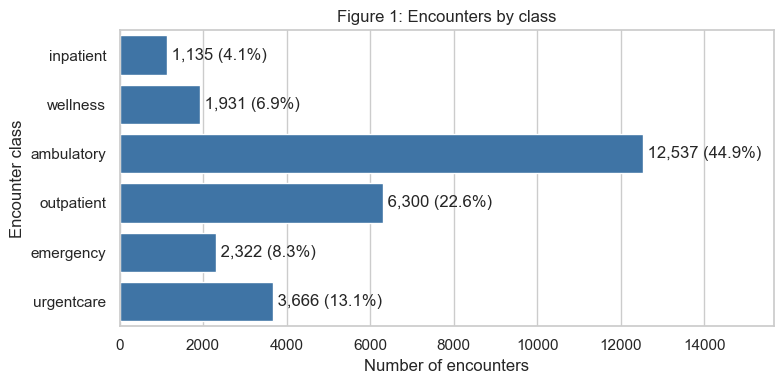

In [7]:
def p95(x):  # helper: 95th percentile
    return x.quantile(0.95)  # return the 95th percentile of a series

cost_by_class = enc.groupby("encounter_class", observed=True)["TOTAL_CLAIM_COST"].agg(  # summary of cost per class
    n="size", mean="mean", median="median", q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75),  # size, mean, median, quartiles
    p95=p95, max="max", zero_cost_n=lambda x: int((x == 0).sum()),  # tail and zero counts
)  # end of aggregation
cost_by_class["share_of_encounters"] = cost_by_class["n"] / cost_by_class["n"].sum()  # each class's share of all encounters
cost_by_class["share_of_total_cost"] = enc.groupby("encounter_class", observed=True)["TOTAL_CLAIM_COST"].sum() / enc["TOTAL_CLAIM_COST"].sum()  # each class's share of total spending
display(cost_by_class)  # show the table
cost_by_class.to_csv(os.path.join(OUTPUT_DIR, "cost_by_class.csv"))  # save for the report

print("\nOverall skewness of TOTAL_CLAIM_COST:", round(enc["TOTAL_CLAIM_COST"].skew(), 2))  # skew > 1 means strongly right-skewed
print("Mean / median ratio:", round(enc["TOTAL_CLAIM_COST"].mean() / enc["TOTAL_CLAIM_COST"].median(), 1))  # large ratio signals skew

fig, ax = plt.subplots(figsize=(8, 4))  # create a figure for the class counts
counts = enc["encounter_class"].value_counts().reindex(order[::-1])  # counts ordered from most to least costly class
sns.barplot(x=counts.values, y=counts.index.astype(str), color="#2E75B6", ax=ax)  # horizontal bar chart of encounter counts
for i, v in enumerate(counts.values):  # loop over bars
    ax.text(v, i, f" {v:,} ({v / len(enc):.1%})", va="center")  # write the count and percentage on each bar
ax.set_xlabel("Number of encounters")  # x-axis label
ax.set_ylabel("Encounter class")  # y-axis label
ax.set_title("Figure 1: Encounters by class")  # chart title
ax.set_xlim(0, counts.max() * 1.25)  # leave room for the labels
plt.tight_layout()  # tidy the layout
fig.savefig(os.path.join(FIG_DIR, "fig1_encounters_by_class.png"), dpi=150)  # save the figure
plt.show()  # display the figure

### Results (Figure 1 and table)
| Class | Encounters | Share of encounters | Median cost | Mean cost | Share of total cost |
|---|---|---|---|---|---|
| ambulatory | 12,537 | 44.9 % | $573.98 | $2,894 | 35.7 % |
| outpatient | 6,300 | 22.6 % | $278.58 | $2,237 | 13.9 % |
| urgentcare | 3,666 | 13.1 % | $142.58 | $6,369 | **23.0 %** |
| emergency | 2,322 | 8.3 % | $146.18 | $4,630 | 10.6 % |
| wellness | 1,931 | 6.9 % | $1,231.44 | $4,261 | 8.1 % |
| inpatient | 1,135 | 4.1 % | $2,355.59 | **$7,761** | 8.7 % |

**What it shows**
- Ambulatory and outpatient together account for **67.5 %** of encounters.
- Costs are extremely right-skewed: overall mean ≈ **13×** the median, skewness 16.3.
- **Medians and means tell different stories.** Urgent care and emergency have the *lowest* medians (≈ $143–146, essentially the base encounter fee) but *high* means, because a minority of encounters carry expensive procedures. Urgent care generates **23 %** of all cost from only 13 % of encounters.
- 89 claims have a zero total (51 wellness, 28 inpatient, 6 emergency, 4 ambulatory).

**What it cannot show:** *why* costs differ – that needs the procedure analysis (H3) and, ideally, diagnosis data.

## 10. EDA – distribution of claim costs and outliers

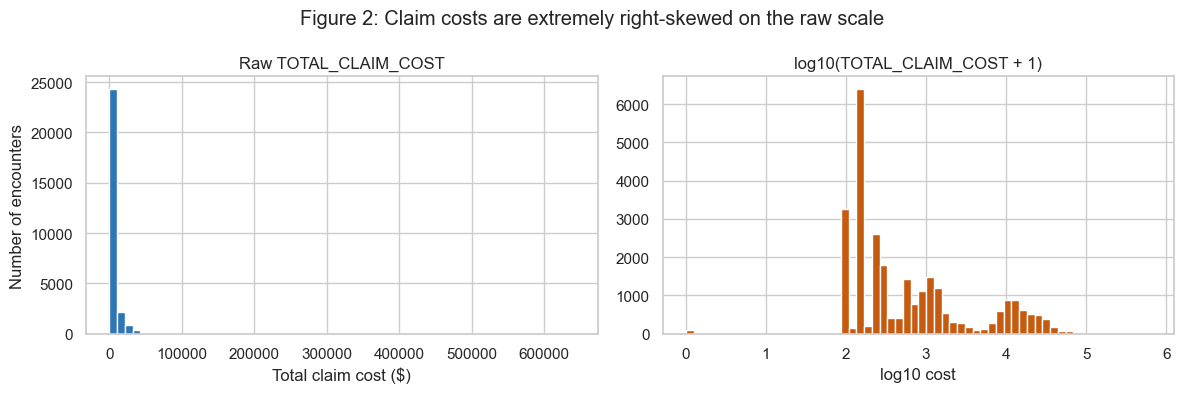

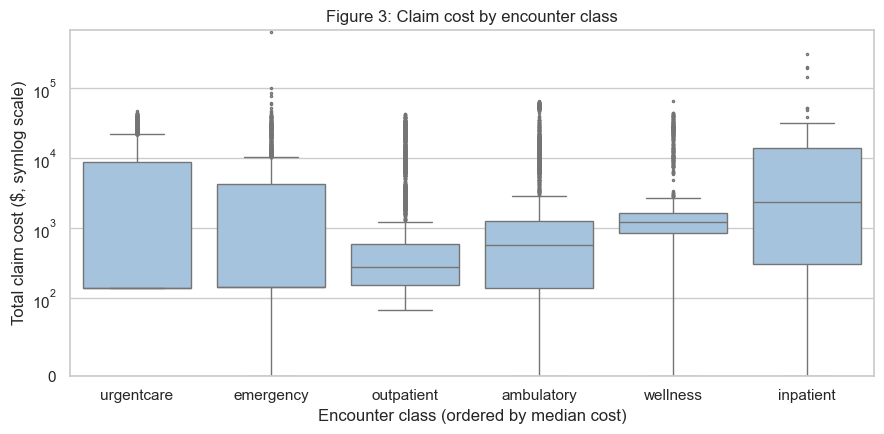

IQR upper fence = $3,317; encounters above it: 5,316 (19.1%)
Top 5 claim costs (class and amount only, no identifiers):
encounter_class  TOTAL_CLAIM_COST  n_procedures
      emergency       641,882.700        10.000
      inpatient       309,748.160        20.000
      inpatient       199,655.260        16.000
      inpatient       198,487.110        14.000
      inpatient       146,473.570        12.000


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # two side-by-side histograms
axes[0].hist(enc["TOTAL_CLAIM_COST"], bins=60, color="#2E75B6")  # raw cost histogram
axes[0].set_title("Raw TOTAL_CLAIM_COST")  # left title
axes[0].set_xlabel("Total claim cost ($)")  # left x label
axes[0].set_ylabel("Number of encounters")  # left y label
axes[1].hist(enc["log_cost"], bins=60, color="#C55A11")  # log-scale histogram
axes[1].set_title("log10(TOTAL_CLAIM_COST + 1)")  # right title
axes[1].set_xlabel("log10 cost")  # right x label
fig.suptitle("Figure 2: Claim costs are extremely right-skewed on the raw scale")  # overall title
plt.tight_layout()  # tidy layout
fig.savefig(os.path.join(FIG_DIR, "fig2_cost_distribution.png"), dpi=150)  # save the figure
plt.show()  # display the figure

fig, ax = plt.subplots(figsize=(9, 4.5))  # figure for the box plot
sns.boxplot(data=enc, x="encounter_class", y="TOTAL_CLAIM_COST", color="#9DC3E6", fliersize=1.5, ax=ax)  # cost distribution by class
ax.set_yscale("symlog", linthresh=100)  # symmetric-log axis so zeros and huge values both show
ax.set_ylim(bottom=0)  # costs cannot be negative, so start the axis at zero
ax.set_xlabel("Encounter class (ordered by median cost)")  # x label
ax.set_ylabel("Total claim cost ($, symlog scale)")  # y label
ax.set_title("Figure 3: Claim cost by encounter class")  # title
plt.tight_layout()  # tidy layout
fig.savefig(os.path.join(FIG_DIR, "fig3_cost_boxplot_by_class.png"), dpi=150)  # save the figure
plt.show()  # display the figure

q1, q3 = enc["TOTAL_CLAIM_COST"].quantile([.25, .75])  # quartiles for the IQR rule
upper_fence = q3 + 1.5 * (q3 - q1)  # classic Tukey upper outlier fence
print(f"IQR upper fence = ${upper_fence:,.0f}; encounters above it: {(enc['TOTAL_CLAIM_COST'] > upper_fence).sum():,} ({(enc['TOTAL_CLAIM_COST'] > upper_fence).mean():.1%})")  # how many outliers
print("Top 5 claim costs (class and amount only, no identifiers):")  # heading
print(enc.nlargest(5, "TOTAL_CLAIM_COST")[["encounter_class", "TOTAL_CLAIM_COST", "n_procedures"]].to_string(index=False))  # the five largest claims

### Results (Figures 2–3)
- **Figure 2:** on the raw scale almost every encounter sits at the far left; the log scale reveals a multi-modal shape (clusters of standard fee levels). A normal-theory test (ANOVA/t-test) would be inappropriate.
- **Figure 3:** the box for inpatient is highest and widest; wellness is narrow and high; outpatient is lowest. Urgent care and emergency boxes start at the floor value (~$143–146) but have very long upper whiskers.
- **Outliers:** the Tukey upper fence is **$3,317**; **5,316 encounters (19.1 %)** exceed it – so "outlier" here is a large, systematic group, not rare errors. The largest claim is **$641,883** (an emergency encounter with 10 procedures); the next four are inpatient (up to $309,748).
- **Decision:** outliers are genuine recorded costs, so they are **kept** and handled with rank-based tests and bootstrap medians.

## 11. EDA – duration and payer coverage

,median,p90,p99,max,pct_over_24h,n_over_24h,pct_exactly_15min
encounter_class,,,,,,,
urgentcare,0.250,0.250,0.250,0.250,0.000,0,1.000
emergency,1.000,1.000,1.713,589.000,0.002,5,0.000
outpatient,0.250,0.250,1.039,"10,704.000",0.001,7,0.916
ambulatory,0.250,3.067,3.900,"44,930.000",0.000,5,0.634
wellness,0.250,0.250,0.250,0.250,0.000,0,1.000
inpatient,24.000,24.000,220.395,"8,250.004",0.051,58,0.000


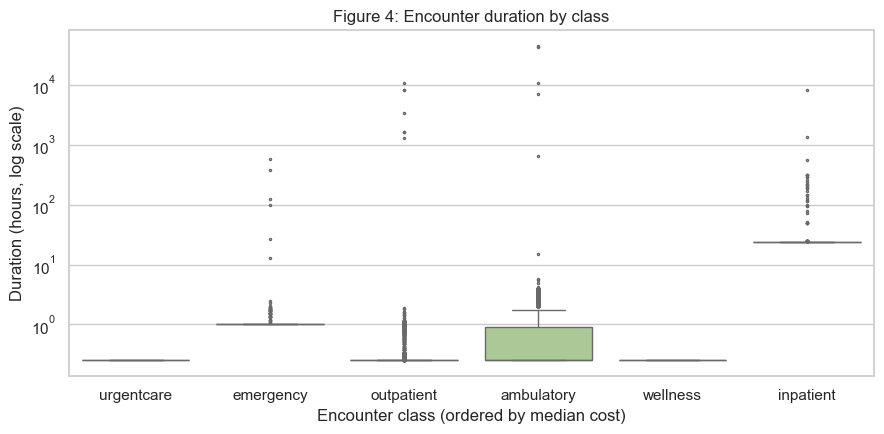

,pct_zero_coverage,median_coverage
encounter_class,,
urgentcare,0.458,80.255
emergency,0.327,84.940
outpatient,0.524,0.000
ambulatory,0.519,0.000
wellness,0.411,623.020
inpatient,0.485,84.940


Overall: 13,586 encounters (48.7%) have zero payer coverage


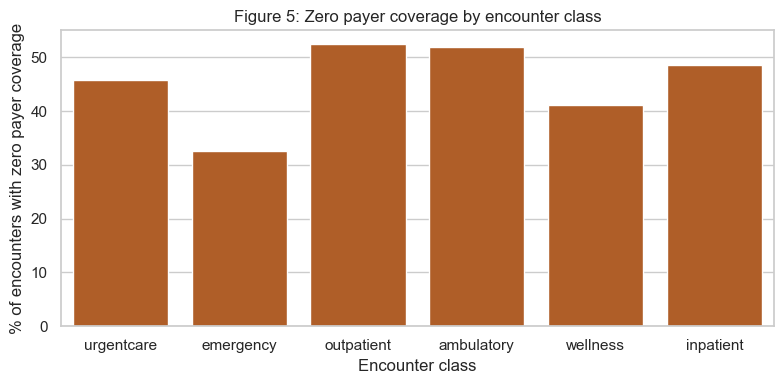

In [9]:
dur_by_class = enc.groupby("encounter_class", observed=True)["duration_hours"].agg(  # duration summary per class
    median="median", p90=lambda x: x.quantile(.9), p99=lambda x: x.quantile(.99), max="max",  # centre and tail
    pct_over_24h=lambda x: (x > 24).mean(), n_over_24h=lambda x: int((x > 24).sum()),  # share and count over 24 hours
    pct_exactly_15min=lambda x: (x == 0.25).mean(),  # share at the default 15-minute length
)  # end of aggregation
display(dur_by_class)  # show the table
dur_by_class.to_csv(os.path.join(OUTPUT_DIR, "duration_by_class.csv"))  # save for the report

fig, ax = plt.subplots(figsize=(9, 4.5))  # figure for duration box plot
sns.boxplot(data=enc, x="encounter_class", y="duration_hours", color="#A9D18E", fliersize=1.5, ax=ax)  # duration by class
ax.set_yscale("log")  # log axis because durations span minutes to years
ax.set_xlabel("Encounter class (ordered by median cost)")  # x label
ax.set_ylabel("Duration (hours, log scale)")  # y label
ax.set_title("Figure 4: Encounter duration by class")  # title
plt.tight_layout()  # tidy layout
fig.savefig(os.path.join(FIG_DIR, "fig4_duration_by_class.png"), dpi=150)  # save the figure
plt.show()  # display the figure

cov = enc.groupby("encounter_class", observed=True).agg(  # payer-coverage summary per class
    pct_zero_coverage=("zero_coverage", "mean"),  # share of encounters with zero payer coverage
    median_coverage=("PAYER_COVERAGE", "median"),  # median amount covered
)  # end of aggregation
display(cov)  # show the table
print(f"Overall: {enc['zero_coverage'].sum():,} encounters ({enc['zero_coverage'].mean():.1%}) have zero payer coverage")  # headline coverage figure

fig, ax = plt.subplots(figsize=(8, 4))  # figure for the coverage bar chart
sns.barplot(x=cov.index.astype(str), y=cov["pct_zero_coverage"] * 100, color="#C55A11", ax=ax)  # % zero coverage per class
ax.set_ylabel("% of encounters with zero payer coverage")  # y label
ax.set_xlabel("Encounter class")  # x label
ax.set_title("Figure 5: Zero payer coverage by encounter class")  # title
plt.tight_layout()  # tidy layout
fig.savefig(os.path.join(FIG_DIR, "fig5_zero_coverage_by_class.png"), dpi=150)  # save the figure
plt.show()  # display the figure

### Results (Figures 4–5 and tables)
- **Inpatient is the only class with long encounters:** median 24 h, **5.1 % (58 encounters) exceed 24 h**. Urgent care and wellness are **always** 15 minutes (zero variation).
- Extreme durations (> 8,000 h) occur in outpatient/ambulatory records, where 91.6 % and 63.4 % of encounters are the 15-minute default – suspicious, open-ended stop times.
- **Payer coverage:** **13,586 encounters (48.7 %) have zero payer coverage.** The share is similar across classes (33 %–52 %); it is lowest in emergency (32.7 %) and highest in outpatient (52.4 %) and ambulatory (51.9 %).

**What it cannot show:** a zero coverage value does not tell us *why* (uninsured, denied claim, patient-paid, or not yet recorded).

## 12. EDA – relationships between variables and consistency checks

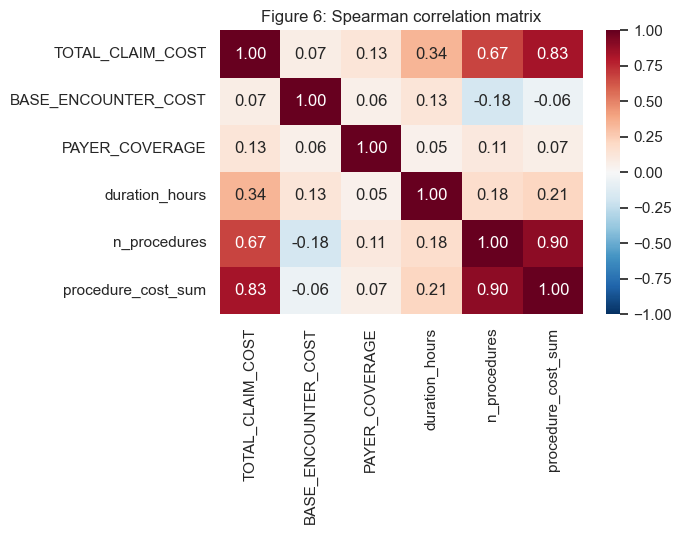

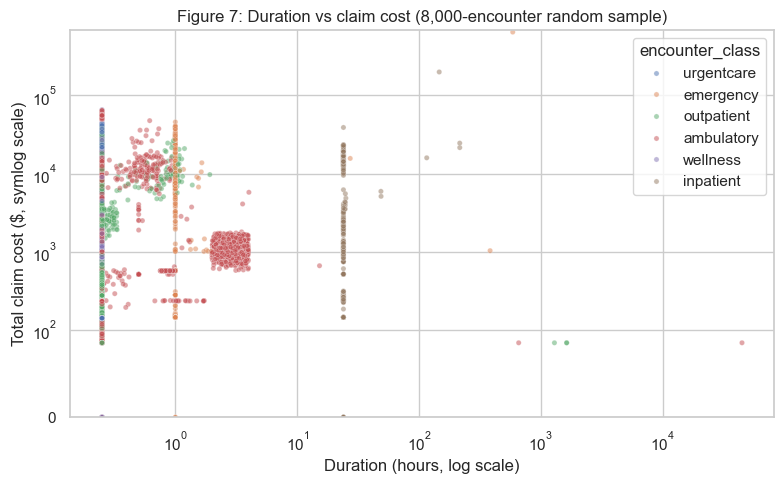

Claims where payer coverage exceeds total cost: 0
Claims lower than the base encounter cost: 89
Share of encounters where TOTAL_CLAIM_COST >= base cost + sum of procedure costs: 74.0%


In [10]:
num_cols = ["TOTAL_CLAIM_COST", "BASE_ENCOUNTER_COST", "PAYER_COVERAGE", "duration_hours", "n_procedures", "procedure_cost_sum"]  # numeric variables to compare
corr = enc[num_cols].corr(method="spearman")  # Spearman is rank-based, so it is robust to skew and outliers
fig, ax = plt.subplots(figsize=(7, 5.5))  # figure for the heatmap
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)  # annotated correlation heatmap
ax.set_title("Figure 6: Spearman correlation matrix")  # title
plt.tight_layout()  # tidy layout
fig.savefig(os.path.join(FIG_DIR, "fig6_spearman_heatmap.png"), dpi=150)  # save the figure
plt.show()  # display the figure

fig, ax = plt.subplots(figsize=(8, 5))  # figure for the scatter plot
sns.scatterplot(data=enc.sample(8000, random_state=42), x="duration_hours", y="TOTAL_CLAIM_COST", hue="encounter_class", s=14, alpha=.5, ax=ax)  # random 8,000-point sample keeps the plot readable
ax.set_xscale("log")  # log x axis for durations
ax.set_yscale("symlog", linthresh=100)  # symlog y axis for costs
ax.set_ylim(bottom=0)  # start the axis at zero
ax.set_xlabel("Duration (hours, log scale)")  # x label
ax.set_ylabel("Total claim cost ($, symlog scale)")  # y label
ax.set_title("Figure 7: Duration vs claim cost (8,000-encounter random sample)")  # title
plt.tight_layout()  # tidy layout
fig.savefig(os.path.join(FIG_DIR, "fig7_duration_vs_cost.png"), dpi=150)  # save the figure
plt.show()  # display the figure

check = enc[["TOTAL_CLAIM_COST", "BASE_ENCOUNTER_COST", "procedure_cost_sum", "PAYER_COVERAGE"]]  # columns for consistency checks
print("Claims where payer coverage exceeds total cost:", int((check["PAYER_COVERAGE"] > check["TOTAL_CLAIM_COST"]).sum()))  # impossible coverage
print("Claims lower than the base encounter cost:", int((check["TOTAL_CLAIM_COST"] < check["BASE_ENCOUNTER_COST"]).sum()))  # total below base
recon = (check["TOTAL_CLAIM_COST"] + 0.01 >= check["BASE_ENCOUNTER_COST"] + check["procedure_cost_sum"])  # does total cover base + procedures?
print(f"Share of encounters where TOTAL_CLAIM_COST >= base cost + sum of procedure costs: {recon.mean():.1%}")  # reconciliation rate

### Results (Figures 6–7 and consistency checks)
- Spearman correlations: claim cost is strongly related to the **sum of procedure costs** (≈ 0.83) and to **number of procedures** (≈ 0.67), and only moderately to duration (≈ 0.34).
- Figure 7 shows duration rising with cost only loosely and in bands, because most points share the 15-minute duration.
- **Consistency checks:** payer coverage never exceeds the claim total (0 cases) ✔. **89 claims are below the base encounter cost** (matching the 89 zero-cost claims). Only **74.0 %** of encounters have `TOTAL_CLAIM_COST ≥ base cost + sum of procedure costs`, so total claim cost **does not always include procedure line items** as the dictionary implies – a definitional ambiguity that must be confirmed with the data owner.

## 13. Hypothesis H1 – Do claim costs differ across encounter classes?
**H0:** the cost distribution is identical in all six classes. **H1:** at least one class differs.

**Method and why.** Kruskal–Wallis H test. *Assumption checks:* Shapiro–Wilk rejects normality even on the log scale (W = 0.887, p ≈ 3e-51) and Brown–Forsythe rejects equal variances (p ≈ 4e-101), so ANOVA is not appropriate. Kruskal–Wallis needs independent observations, an ordinal-or-better outcome, and (for a *median* interpretation) similar distribution shapes. Shapes differ, so the test is interpreted as "tends to have higher/lower values" (stochastic dominance), not as an exact median difference. Independence is violated by repeated patients – hence the sensitivity analysis.


Shapiro-Wilk on log cost: W = 0.887, p = 2.87e-51  -> normality rejected
Brown-Forsythe (Levene) on log cost: stat = 96.4, p = 4.24e-101  -> equal variances rejected

Kruskal-Wallis: H = 2,025.2, df = 5, p = 0.00e+00, effect size (eta^2_H) = 0.072


,class_a,class_b,cliffs_delta,p_raw,p_bonferroni,significant
0,urgentcare,emergency,-0.384,0.000,0.000,True
1,urgentcare,outpatient,-0.077,0.000,0.000,True
2,urgentcare,ambulatory,-0.088,0.000,0.000,True
3,urgentcare,wellness,-0.442,0.000,0.000,True
4,urgentcare,inpatient,-0.443,0.000,0.000,True
5,emergency,outpatient,-0.073,0.000,0.000,True
6,emergency,ambulatory,-0.006,0.644,1.000,False
7,emergency,wellness,-0.452,0.000,0.000,True
8,emergency,inpatient,-0.480,0.000,0.000,True
9,outpatient,ambulatory,-0.099,0.000,0.000,True


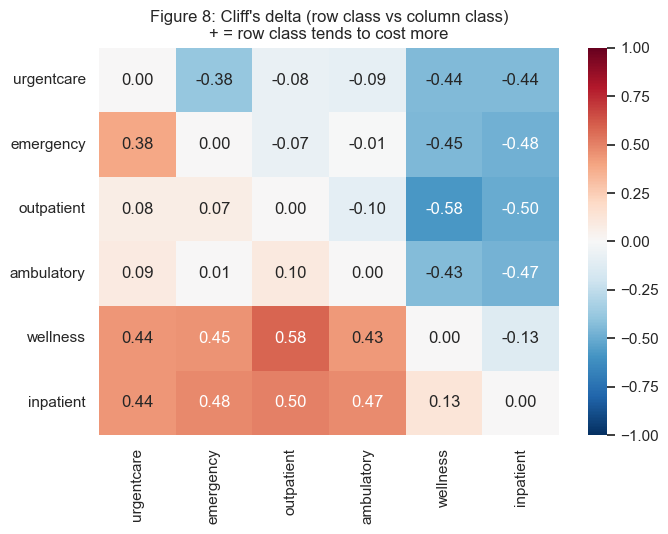

,class,n,median,ci_low,ci_high
0,urgentcare,3666,142.580,142.580,142.580
1,emergency,2322,146.180,146.180,146.180
2,outpatient,6300,278.580,278.580,278.580
3,ambulatory,12537,573.980,448.129,573.980
4,wellness,1931,"1,231.440","1,199.940","1,257.380"
5,inpatient,1135,"2,355.590","1,934.209","2,682.610"


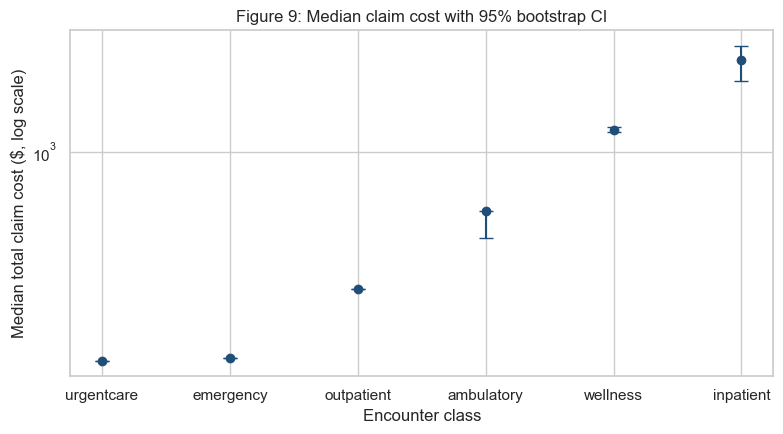


Sensitivity (one encounter per patient, n = 974): H = 100.5, p = 4.14e-20, eta^2_H = 0.099


In [11]:
ALPHA = 0.05  # significance level used for all tests
groups = [g["TOTAL_CLAIM_COST"].to_numpy() for _, g in enc.groupby("encounter_class", observed=True)]  # one cost array per class
k, n = len(groups), len(enc)  # number of groups and total observations

sample_log = enc["log_cost"].sample(5000, random_state=42)  # Shapiro-Wilk is only reliable up to ~5,000 points
sh_stat, sh_p = stats.shapiro(sample_log)  # normality test on the log-scale costs
lev_stat, lev_p = stats.levene(*[np.log10(g + 1) for g in groups], center="median")  # Brown-Forsythe test for equal variances
print(f"Shapiro-Wilk on log cost: W = {sh_stat:.3f}, p = {sh_p:.2e}  -> normality {'rejected' if sh_p < ALPHA else 'not rejected'}")  # normality verdict
print(f"Brown-Forsythe (Levene) on log cost: stat = {lev_stat:.1f}, p = {lev_p:.2e}  -> equal variances {'rejected' if lev_p < ALPHA else 'not rejected'}")  # variance verdict

H, p_kw = stats.kruskal(*groups)  # Kruskal-Wallis H test across all six classes
eps2 = (H - k + 1) / (n - k)  # epsilon-squared style effect size for Kruskal-Wallis (share of rank variance explained)
print(f"\nKruskal-Wallis: H = {H:,.1f}, df = {k - 1}, p = {p_kw:.2e}, effect size (eta^2_H) = {eps2:.3f}")  # headline H1 result

names = [str(c) for c in order]  # class names in the chosen order
by_class = {c: enc.loc[enc["encounter_class"] == c, "TOTAL_CLAIM_COST"].to_numpy() for c in order}  # cost arrays keyed by class
rows = []  # list that will hold the pairwise results
pairs = list(itertools.combinations(order, 2))  # every pair of classes (15 pairs)
for a, b in pairs:  # loop over the pairs
    u, p = stats.mannwhitneyu(by_class[a], by_class[b], alternative="two-sided")  # Mann-Whitney U test for this pair
    delta = 2 * u / (len(by_class[a]) * len(by_class[b])) - 1  # Cliff's delta: >0 means class a tends to cost MORE than b
    rows.append({"class_a": a, "class_b": b, "cliffs_delta": delta, "p_raw": p, "p_bonferroni": min(p * len(pairs), 1.0)})  # store results
posthoc = pd.DataFrame(rows)  # convert to a table
posthoc["significant"] = posthoc["p_bonferroni"] < ALPHA  # Bonferroni-adjusted decision
display(posthoc)  # show all pairwise comparisons
posthoc.to_csv(os.path.join(OUTPUT_DIR, "posthoc_pairwise.csv"), index=False)  # save for the report

mat = pd.DataFrame(0.0, index=names, columns=names)  # empty matrix for the heatmap
for _, r in posthoc.iterrows():  # fill the matrix from the pairwise table
    mat.loc[str(r.class_a), str(r.class_b)] = r.cliffs_delta  # a vs b
    mat.loc[str(r.class_b), str(r.class_a)] = -r.cliffs_delta  # b vs a (sign flips)
fig, ax = plt.subplots(figsize=(7, 5.5))  # figure for the heatmap
sns.heatmap(mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)  # effect-size heatmap
ax.set_title("Figure 8: Cliff's delta (row class vs column class)\n+ = row class tends to cost more")  # title
plt.tight_layout()  # tidy layout
fig.savefig(os.path.join(FIG_DIR, "fig8_posthoc_cliffs_delta.png"), dpi=150)  # save the figure
plt.show()  # display the figure

B = 1000  # number of bootstrap resamples
ci_rows = []  # list for bootstrap results
for c in order:  # loop over classes
    x = by_class[c]  # costs for this class
    meds = np.median(RNG.choice(x, size=(B, len(x)), replace=True), axis=1)  # median of each bootstrap resample
    ci_rows.append({"class": str(c), "n": len(x), "median": np.median(x), "ci_low": np.percentile(meds, 2.5), "ci_high": np.percentile(meds, 97.5)})  # 95% percentile CI
ci = pd.DataFrame(ci_rows)  # table of medians and CIs
display(ci)  # show the table
ci.to_csv(os.path.join(OUTPUT_DIR, "median_cost_bootstrap_ci.csv"), index=False)  # save for the report

fig, ax = plt.subplots(figsize=(8, 4.5))  # figure for the CI plot
ax.errorbar(ci["class"], ci["median"], yerr=[ci["median"] - ci["ci_low"], ci["ci_high"] - ci["median"]], fmt="o", capsize=5, color="#1F4E79")  # medians with 95% CIs
ax.set_yscale("log")  # log axis because medians differ by an order of magnitude
ax.set_xlabel("Encounter class")  # x label
ax.set_ylabel("Median total claim cost ($, log scale)")  # y label
ax.set_title("Figure 9: Median claim cost with 95% bootstrap CI")  # title
plt.tight_layout()  # tidy layout
fig.savefig(os.path.join(FIG_DIR, "fig9_median_cost_ci.png"), dpi=150)  # save the figure
plt.show()  # display the figure

one_per_patient = enc.sample(frac=1, random_state=42).drop_duplicates("PATIENT")  # keep ONE random encounter per patient so observations are independent
g_sens = [g["TOTAL_CLAIM_COST"].to_numpy() for _, g in one_per_patient.groupby("encounter_class", observed=True) if len(g) > 1]  # cost arrays for the sensitivity sample
H_s, p_s = stats.kruskal(*g_sens)  # Kruskal-Wallis on the independent sample
print(f"\nSensitivity (one encounter per patient, n = {len(one_per_patient):,}): H = {H_s:,.1f}, p = {p_s:.2e}, eta^2_H = {(H_s - len(g_sens) + 1) / (len(one_per_patient) - len(g_sens)):.3f}")  # robustness result

### Results
| Result | Value |
|---|---|
| Kruskal–Wallis | **H = 2,025.2, df = 5, p < 1e-300** (software prints 0) |
| Effect size (η²_H) | **0.072** – a moderate effect: class explains ≈ 7 % of the rank variation |
| Sensitivity: one encounter per patient (n = 974) | H = 100.5, p = 4.1e-20, η²_H = 0.099 → **same conclusion** |

**Post-hoc (Mann–Whitney, Bonferroni × 15):** 14 of 15 pairs differ significantly. The **only non-significant pair is emergency vs ambulatory** (δ = −0.006, adjusted p = 1.0). Largest effects (Cliff's δ; negative = first class cheaper): outpatient vs wellness −0.58, inpatient vs outpatient +0.50, inpatient vs emergency +0.48, inpatient vs ambulatory +0.47. Wellness vs inpatient is small (−0.13).

**Bootstrap 95 % CIs for the median:** ambulatory $448–$574, wellness $1,200–$1,257, inpatient $1,934–$2,683. For urgent care, emergency and outpatient the CI collapses to a single value ($142.58, $146.18, $278.58) because the median equals the most common fee level; this indicates *stability*, not an error.

### Plain-language interpretation
**Yes – claim costs clearly differ by encounter class.** Inpatient encounters typically cost the most (median about 16× an urgent-care encounter: $2,356 vs $143), followed by wellness, ambulatory and outpatient; urgent care and emergency typically cost the least. Emergency and ambulatory are statistically indistinguishable in rank terms.

**Practical significance:** with 27,891 records, tiny differences become "significant", so the effect sizes matter: the class effect is moderate overall and large for pairs such as outpatient vs wellness or inpatient vs outpatient. **Caution:** the ordering by *typical* (median) cost differs from the ordering by *average* cost, which is dominated by procedure-heavy encounters (urgent care mean $6,369 > inpatient median $2,356).

## 14. Hypothesis H2 – Is encounter duration associated with claim cost?
**H0:** ρ = 0 (no monotonic association). **H1:** ρ ≠ 0.

**Method and why.** Spearman rank correlation, because both variables are highly skewed with outliers and ties (Pearson would be dominated by a handful of extreme values). Assumptions: a monotonic (not necessarily linear) relationship and independent observations. **Heavy ties** (69 % of durations are 15 min) reduce resolution, and repeated patients break independence (sensitivity analysis included). Confounding by class is handled by within-class and partial correlations.


In [12]:
rho, p_rho = stats.spearmanr(enc["duration_hours"], enc["TOTAL_CLAIM_COST"])  # overall Spearman correlation
boot = []  # list for bootstrap correlations
for _ in range(300):  # 300 bootstrap resamples
    idx = RNG.integers(0, n, n)  # random row positions with replacement
    boot.append(stats.spearmanr(enc["duration_hours"].to_numpy()[idx], enc["TOTAL_CLAIM_COST"].to_numpy()[idx])[0])  # correlation of the resample
lo, hi = np.percentile(boot, [2.5, 97.5])  # 95% bootstrap confidence interval
print(f"Overall Spearman rho = {rho:.3f} (95% CI {lo:.3f} to {hi:.3f}), p = {p_rho:.2e}, n = {n:,}")  # headline H2 result

within = []  # list for within-class correlations
for c in order:  # loop over classes
    d = enc[enc["encounter_class"] == c]  # rows of this class
    if d["duration_hours"].nunique() > 1 and d["TOTAL_CLAIM_COST"].nunique() > 1:  # correlation needs variation in both variables
        r_c, p_c = stats.spearmanr(d["duration_hours"], d["TOTAL_CLAIM_COST"])  # within-class Spearman
    else:  # otherwise the correlation is undefined
        r_c, p_c = np.nan, np.nan  # e.g. every duration is exactly 15 minutes
    within.append({"class": str(c), "n": len(d), "distinct_durations": d["duration_hours"].nunique(), "spearman_rho": r_c, "p_value": p_c})  # store row
within = pd.DataFrame(within)  # table of within-class results
within["p_bonferroni"] = (within["p_value"] * within["p_value"].notna().sum()).clip(upper=1)  # adjust for multiple classes
display(within)  # show the table
within.to_csv(os.path.join(OUTPUT_DIR, "duration_cost_within_class.csv"), index=False)  # save for the report

rank_dur = stats.rankdata(enc["duration_hours"])  # ranks of duration
rank_cost = stats.rankdata(enc["TOTAL_CLAIM_COST"])  # ranks of cost
X = pd.get_dummies(enc["encounter_class"], drop_first=True).astype(float).to_numpy()  # class dummy variables
X = np.column_stack([np.ones(n), X])  # add an intercept column
res_dur = rank_dur - X @ np.linalg.lstsq(X, rank_dur, rcond=None)[0]  # duration ranks with class effect removed
res_cost = rank_cost - X @ np.linalg.lstsq(X, rank_cost, rcond=None)[0]  # cost ranks with class effect removed
r_partial = np.corrcoef(res_dur, res_cost)[0, 1]  # partial rank correlation controlling for class
t_stat = r_partial * np.sqrt((n - 2 - X.shape[1] + 1) / (1 - r_partial ** 2))  # t statistic for the partial correlation
p_partial = 2 * stats.t.sf(abs(t_stat), df=n - 2 - X.shape[1] + 1)  # two-sided p-value
print(f"\nPartial Spearman rho (controlling for encounter class) = {r_partial:.3f}, p = {p_partial:.2e}")  # confounding-adjusted result

rho_s, p_s2 = stats.spearmanr(one_per_patient["duration_hours"], one_per_patient["TOTAL_CLAIM_COST"])  # sensitivity: one encounter per patient
cap = enc["duration_hours"].quantile(0.99)  # 99th percentile of duration
trim = enc[enc["duration_hours"] <= cap]  # drop the longest 1% of durations
rho_t, p_t = stats.spearmanr(trim["duration_hours"], trim["TOTAL_CLAIM_COST"])  # sensitivity: trimmed durations
print(f"Sensitivity - one encounter per patient: rho = {rho_s:.3f} (p = {p_s2:.1e}); durations <= 99th pct ({cap:.2f}h): rho = {rho_t:.3f} (p = {p_t:.1e})")  # robustness results

enc["duration_band"] = pd.cut(enc["duration_hours"], bins=[0, 0.25, 1, 24, np.inf], labels=["<=15 min", "15 min-1 h", "1-24 h", ">24 h"], include_lowest=True)  # practical duration bands
band = enc.groupby("duration_band", observed=True).agg(n=("Id", "size"), median_cost=("TOTAL_CLAIM_COST", "median"), mean_cost=("TOTAL_CLAIM_COST", "mean"))  # cost by band
display(band)  # show the table

Overall Spearman rho = 0.338 (95% CI 0.329 to 0.347), p = 0.00e+00, n = 27,891


,class,n,distinct_durations,spearman_rho,p_value,p_bonferroni
0,urgentcare,3666,1,NaN,NaN,NaN
1,emergency,2322,38,0.166,0.000,0.000
2,outpatient,6300,445,0.393,0.000,0.000
3,ambulatory,12537,1379,0.477,0.000,0.000
4,wellness,1931,1,NaN,NaN,NaN
5,inpatient,1135,59,0.173,0.000,0.000



Partial Spearman rho (controlling for encounter class) = 0.391, p = 0.00e+00
Sensitivity - one encounter per patient: rho = 0.340 (p = 8.4e-28); durations <= 99th pct (24.00h): rho = 0.336 (p = 0.0e+00)


,n,median_cost,mean_cost
duration_band,,,
<=15 min,19313,234.720,"3,428.813"
15 min-1 h,4497,573.980,"4,821.928"
1-24 h,4006,"1,135.730","2,882.003"
>24 h,75,"4,860.470","27,522.479"


### Results
| Analysis | ρ | Note |
|---|---|---|
| **Overall** (n = 27,891) | **0.338** (95 % CI 0.329–0.347), p < 1e-300 | Weak-to-moderate positive |
| Within ambulatory | 0.477 | Strongest |
| Within outpatient | 0.393 | |
| Within inpatient | 0.173 | Weak |
| Within emergency | 0.166 | Weak |
| Urgent care, wellness | undefined | Every duration is 15 min (no variation) |
| **Partial ρ controlling for class** | **0.391** | Association is *not* just a class effect |
| One encounter per patient (n = 974) | 0.340 | Same result |
| Durations ≤ 99th percentile (24 h) | 0.336 | Not driven by extreme durations |

**Cost by duration band (median):** ≤ 15 min $234.72 (n = 19,313) → 15 min–1 h $573.98 (n = 4,497) → 1–24 h $1,135.73 (n = 4,006) → > 24 h $4,860.47 (n = 75).

### Plain-language interpretation
**Longer encounters tend to carry higher recorded costs**, and this holds even after allowing for encounter class, with and without extreme durations, and using independent observations. The association is **weak-to-moderate** (ρ ≈ 0.34–0.39): knowing the duration only partly predicts the cost. Medians rise steadily across duration bands, but *means* do not (the ≤ 15 min band has a higher mean than the 1–24 h band) because short urgent-care/wellness encounters with expensive procedures inflate it.

**Practical significance and limits:** duration is a usable but *imperfect* cost signal, and its quality is poor (default 15-minute values, four multi-year records). This is **association, not causation** – longer encounters may involve more services (and hence higher cost), rather than time itself driving cost.

## 15. Hypothesis H3 – Do encounters with a recorded procedure cost more?
**H0:** cost distributions are the same with and without a procedure. **H1:** they differ.

**Method and why.** Mann–Whitney U (two independent groups, skewed outcome) with Cliff's delta effect size, repeated **within each class** to control for class confounding, with Bonferroni adjustment across the six classes. Assumptions: independent observations (repeated patients – a limitation) and ordinal-or-better outcome.


With procedures: n = 14,670, median = $1,306.15 | Without: n = 13,221, median = $142.58
Mann-Whitney U = 183,422,588, p = 0.00e+00, Cliff's delta = 0.891


,class,n_with,n_without,median_with,median_without,cliffs_delta,p_value,p_bonferroni
0,urgentcare,1039,2627,"22,598.020",142.580,1.000,0.000,0.000
1,emergency,725,1597,"10,233.450",146.180,0.982,0.000,0.000
2,outpatient,3317,2983,511.500,163.400,0.691,0.000,0.000
3,ambulatory,6851,5686,"1,165.890",142.580,0.916,0.000,0.000
4,wellness,1693,238,"1,278.450",778.780,0.497,0.000,0.000
5,inpatient,1045,90,"2,811.950",146.180,0.973,0.000,0.000



Among encounters with procedures: Spearman rho (procedure cost sum vs total claim cost) = 0.750, p = 0.00e+00


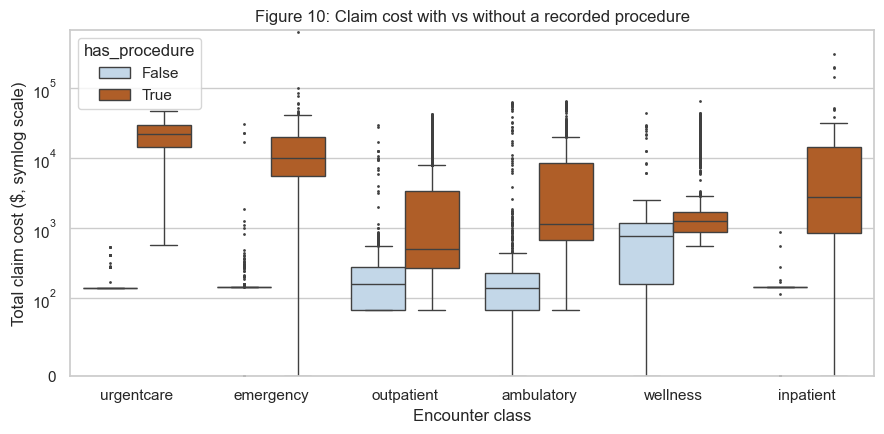

In [13]:
with_p = enc.loc[enc["has_procedure"], "TOTAL_CLAIM_COST"].to_numpy()  # costs of encounters that had procedures
without_p = enc.loc[~enc["has_procedure"], "TOTAL_CLAIM_COST"].to_numpy()  # costs of encounters without procedures
u3, p3 = stats.mannwhitneyu(with_p, without_p, alternative="two-sided")  # Mann-Whitney U test
delta3 = 2 * u3 / (len(with_p) * len(without_p)) - 1  # Cliff's delta (>0 means procedures go with higher cost)
print(f"With procedures: n = {len(with_p):,}, median = ${np.median(with_p):,.2f} | Without: n = {len(without_p):,}, median = ${np.median(without_p):,.2f}")  # group summaries
print(f"Mann-Whitney U = {u3:,.0f}, p = {p3:.2e}, Cliff's delta = {delta3:.3f}")  # headline H3 result

rows3 = []  # list for the stratified results
for c in order:  # repeat the comparison inside each encounter class
    d = enc[enc["encounter_class"] == c]  # rows of this class
    a_, b_ = d.loc[d["has_procedure"], "TOTAL_CLAIM_COST"], d.loc[~d["has_procedure"], "TOTAL_CLAIM_COST"]  # with / without procedures
    if len(a_) >= 10 and len(b_) >= 10:  # need enough observations in both groups
        u_, p_ = stats.mannwhitneyu(a_, b_, alternative="two-sided")  # test inside this class
        rows3.append({"class": str(c), "n_with": len(a_), "n_without": len(b_), "median_with": a_.median(), "median_without": b_.median(), "cliffs_delta": 2 * u_ / (len(a_) * len(b_)) - 1, "p_value": p_})  # store the row
    else:  # too few observations in one group
        rows3.append({"class": str(c), "n_with": len(a_), "n_without": len(b_), "median_with": a_.median(), "median_without": b_.median(), "cliffs_delta": np.nan, "p_value": np.nan})  # record sizes only
strat = pd.DataFrame(rows3)  # stratified table
strat["p_bonferroni"] = (strat["p_value"] * strat["p_value"].notna().sum()).clip(upper=1)  # adjust for multiple classes
display(strat)  # show the table
strat.to_csv(os.path.join(OUTPUT_DIR, "procedure_effect_by_class.csv"), index=False)  # save for the report

has_p = enc[enc["has_procedure"]]  # encounters with procedures only
r_pc, p_pc = stats.spearmanr(has_p["procedure_cost_sum"], has_p["TOTAL_CLAIM_COST"])  # procedure cost vs claim cost
print(f"\nAmong encounters with procedures: Spearman rho (procedure cost sum vs total claim cost) = {r_pc:.3f}, p = {p_pc:.2e}")  # strength of the link

fig, ax = plt.subplots(figsize=(9, 4.5))  # figure for the grouped box plot
sns.boxplot(data=enc, x="encounter_class", y="TOTAL_CLAIM_COST", hue="has_procedure", palette=["#BDD7EE", "#C55A11"], fliersize=1, ax=ax)  # cost by class and procedure flag
ax.set_yscale("symlog", linthresh=100)  # symlog axis
ax.set_ylim(bottom=0)  # start the axis at zero
ax.set_xlabel("Encounter class")  # x label
ax.set_ylabel("Total claim cost ($, symlog scale)")  # y label
ax.set_title("Figure 10: Claim cost with vs without a recorded procedure")  # title
plt.tight_layout()  # tidy layout
fig.savefig(os.path.join(FIG_DIR, "fig10_cost_by_procedure_flag.png"), dpi=150)  # save the figure
plt.show()  # display the figure

### Results
| Result | Value |
|---|---|
| With a procedure (n = 14,670) vs without (n = 13,221) | median **$1,306.15 vs $142.58** |
| Mann–Whitney U | 183,422,588, p < 1e-300 |
| Cliff's δ | **0.891** (very large – a randomly chosen procedure-bearing encounter costs more than a randomly chosen one without in ≈ 95 % of pairs, i.e. (δ+1)/2) |
| Within-class δ | urgent care 1.00, emergency 0.98, inpatient 0.97, ambulatory 0.92, outpatient 0.69, wellness 0.50 (all p_adj < 0.001) |
| Procedure-cost sum vs claim cost (encounters with procedures) | Spearman ρ = **0.750** |

### Plain-language interpretation
Having a recorded procedure is **by far the strongest cost association found** – much stronger than class or duration – and the pattern holds in every class. Urgent-care encounters with procedures have a median claim of **$22,598 versus $142.58** without. **Practical significance:** cost monitoring should focus on procedure-bearing encounters. **Limits:** because claim totals *include* procedure charges by design, this partly measures how the cost is built rather than an independent discovery; and only 74 % of claims reconcile with base cost + procedure cost, so the definition of `TOTAL_CLAIM_COST` should be confirmed with the data owner. Association only – no claim is made about whether procedures were clinically necessary.

## 16. Investigating limitations (Track B Task 4)

| Issue | Effect on conclusions | How it was handled |
|---|---|---|
| **Missing values** | Reason/diagnosis codes 70–78 % empty, so costs cannot be adjusted for condition | Treated as structurally missing; not imputed; excluded from tests |
| **Zero and default values** | 89 zero-cost claims; 48.7 % zero payer coverage; 69 % of durations exactly 15 min (100 % in urgent care and wellness) | Kept as recorded; rank-based methods; within-class results flagged "undefined" where no variation |
| **Unequal group sizes** | Ambulatory n = 12,537 vs inpatient n = 1,135: tiny effects are "significant" in large groups; inpatient estimates are less precise | Reported effect sizes (η²_H, Cliff's δ) and bootstrap CIs, not p-values alone |
| **Repeated records** | 974 patients contribute 27,891 encounters (one has 1,381), so observations are not independent and p-values are too optimistic | One-encounter-per-patient sensitivity analysis for H1 and H2 – conclusions unchanged |
| **Confounding** | Class, procedures, duration and payer are intertwined (e.g. long encounters are mostly inpatient) | Within-class tests, partial correlation, stratified H3. Remaining confounders (diagnosis, age, severity, payer mix) are unmeasured or unused |
| **Outliers** | 5,316 claims above the IQR fence; 4 durations > 1 year | Kept (genuine records); robust methods |
| **Inconsistent definitions** | Only 74 % of claims ≥ base cost + procedure costs; 53 encounters after death date | Documented; must be confirmed with the data owner |
| **Limited coverage** | One hospital; 2022 partial; costs not inflation-adjusted; currency assumed USD; the data may be simulated (e.g. default timings) | Findings describe *this dataset* and should not be generalised |
| **Association vs causation** | Results are observational | Wording avoids causal claims; no clinical claims made |

## 17. Validation – independent checks against the success criteria

In [14]:
# ---- Check 1: independent recomputation of the Kruskal-Wallis H statistic from raw ranks ----
ranks = stats.rankdata(enc["TOTAL_CLAIM_COST"])  # rank every cost (ties get average ranks)
rank_sum = pd.Series(ranks).groupby(enc["encounter_class"].to_numpy()).agg(["sum", "size"])  # rank sum and size per class
H_manual = 12 / (n * (n + 1)) * (rank_sum["sum"] ** 2 / rank_sum["size"]).sum() - 3 * (n + 1)  # textbook H formula
_, counts_t = np.unique(enc["TOTAL_CLAIM_COST"], return_counts=True)  # tie group sizes
tie_corr = 1 - (counts_t ** 3 - counts_t).sum() / (n ** 3 - n)  # correction factor for tied values
H_manual = H_manual / tie_corr  # tie-corrected H
c1 = abs(H_manual - H) < 1e-6 * max(1, abs(H))  # manual and scipy results must agree
# ---- Check 2: group counts and cost totals reconcile with an independent calculation ----
c2 = (cost_by_class["n"].sum() == len(encounters)) and np.isclose(enc.groupby("encounter_class", observed=True)["TOTAL_CLAIM_COST"].sum().sum(), encounters["TOTAL_CLAIM_COST"].sum())  # class totals equal the raw-file totals
# ---- Check 3: per-class medians match a pure-numpy calculation ----
c3 = all(np.isclose(np.median(by_class[c]), cost_by_class.loc[c, "median"]) for c in order)  # numpy median equals pandas median
# ---- Check 4: bootstrap CIs contain the sample medians ----
c4 = bool(((ci["ci_low"] <= ci["median"]) & (ci["median"] <= ci["ci_high"])).all())  # every CI brackets its median
# ---- Check 5: conclusions are stable in a sensitivity analysis ----
c5 = (np.sign(rho) == np.sign(rho_s)) and (p_s < ALPHA)  # same direction for duration/cost and class effect still significant
# ---- Check 6: no rows lost and no values imputed ----
c6 = (len(enc) == len(encounters)) and (enc["TOTAL_CLAIM_COST"].equals(encounters["TOTAL_CLAIM_COST"]))  # raw values untouched
criteria = pd.DataFrame({  # assemble the success-criteria scorecard
    "success criterion": [  # list of criteria
        "1. Manual Kruskal-Wallis H equals scipy H",  # criterion 1
        "2. Class counts and cost totals reconcile with raw file",  # criterion 2
        "3. Class medians match independent numpy calculation",  # criterion 3
        "4. Bootstrap CIs bracket the sample medians",  # criterion 4
        "5. Findings hold in one-encounter-per-patient sensitivity test",  # criterion 5
        "6. No rows dropped and no cost values altered",  # criterion 6
    ],  # end of criteria
    "result": ["PASS" if c else "FAIL" for c in [c1, c2, c3, c4, c5, c6]],  # PASS/FAIL flags
    "detail": [f"manual H = {H_manual:,.2f} vs scipy H = {H:,.2f}", f"n = {cost_by_class['n'].sum():,}", "7 decimals tolerance", "all 6 classes", f"rho {rho:.3f} vs {rho_s:.3f}; p = {p_s:.1e}", f"{len(enc):,} rows kept"],  # evidence shown next to each check
})  # end of table
display(criteria)  # show the scorecard
criteria.to_csv(os.path.join(OUTPUT_DIR, "validation_scorecard.csv"), index=False)  # save as validation evidence

,success criterion,result,detail
0,1. Manual Kruskal-Wallis H equals scipy H,PASS,"manual H = 2,025.19 vs scipy H = 2,025.19"
1,2. Class counts and cost totals reconcile with...,PASS,"n = 27,891"
2,3. Class medians match independent numpy calcu...,PASS,7 decimals tolerance
3,4. Bootstrap CIs bracket the sample medians,PASS,all 6 classes
4,5. Findings hold in one-encounter-per-patient ...,PASS,rho 0.338 vs 0.340; p = 4.1e-20
5,6. No rows dropped and no cost values altered,PASS,"27,891 rows kept"


### Validation evidence (Deliverable 5 / success criteria)
All six pre-defined criteria **PASS**:
1. Manual tie-corrected Kruskal–Wallis H = 2,025.19 equals SciPy's H.
2. 27,891 records and total cost reconcile between the prepared table and the raw CSV.
3. Class medians match an independent NumPy calculation.
4. Every bootstrap CI brackets its median.
5. Conclusions are unchanged using one encounter per patient (ρ 0.338 vs 0.340; H1 still p ≈ 4e-20).
6. No rows dropped and no cost values altered.

`outputs/validation_scorecard.csv` is saved as evidence. A tolerance of `1e-6` is used for the H check because floating-point arithmetic can differ in the last digits.

## 18. Analytical report (summary)

**Research question and objectives.** Determine how claim costs vary by encounter class and whether duration and procedures are associated with cost, to guide operational cost review.

**Data preparation.** Six files inspected; all keys join at 100 %; no duplicates; nothing dropped or imputed; timestamps parsed; log-cost, procedure aggregates and duration created.

**Exploratory findings.** 27,891 encounters (2011–Feb 2022) at one hospital; ambulatory is 44.9 % of volume; costs are extremely skewed (mean ≈ 13× median); urgent care produces 23 % of cost from 13 % of encounters; 48.7 % of encounters have zero payer coverage; duration is coarse (69 % at 15 min).

**Hypotheses and methods.** H1 Kruskal–Wallis + post-hoc + effect sizes; H2 Spearman (overall, within class, partial); H3 Mann–Whitney (overall and stratified). Methods chosen because of skewness, unequal variances, ties and outliers.

**Results.** H1: class differences are significant with a moderate effect (η²_H = 0.072; robust at 0.099 with independent data). H2: duration and cost are positively associated (ρ = 0.34; 0.39 after adjusting for class). H3: procedures are the strongest association (δ = 0.89; ρ = 0.75 with procedure cost).

**Limitations.** See section 16.

## 19. Findings and recommendations

| # | Finding (evidence) | Recommended action | Intended benefit | Limitation / information needed |
|---|---|---|---|---|
| 1 | Procedures are the strongest cost association (δ = 0.89; ρ = 0.75). Urgent-care encounters with procedures have a median claim of $22,598 vs $143 without, and urgent care yields 23 % of cost from 13 % of encounters | Prioritise cost and coding review on procedure-bearing encounters, starting with urgent care | Focuses review effort where most cost arises | Need procedure/charge definitions and diagnosis data to judge appropriateness; no clinical conclusion is drawn |
| 2 | Typical (median) cost and average cost give different class rankings (e.g. urgent care median $143, mean $6,369) | Report **both** median and mean (plus share of total cost) in operational reports; avoid mean-only summaries | Prevents misleading budget decisions | Needs agreement with finance on the standard metric |
| 3 | Duration is only weakly-moderately related to cost (ρ ≈ 0.34–0.39) and poorly recorded (69 % exactly 15 min; 4 records > 1 year; 53 encounters after death date) | Require valid stop times; add validation rules and flag implausible durations | More reliable length-of-stay measures | Need to know whether 15 min is a system default |
| 4 | 48.7 % of encounters have zero payer coverage; only 74 % of claims reconcile with base + procedure cost; 89 claims are zero | Confirm with the data owner what zero coverage means and how `TOTAL_CLAIM_COST` is built; reconcile before using the data for billing decisions | Trustworthy coverage and cost metrics | Need payer-level coverage and billing-process documentation |
| 5 | Class differences are moderate (η²_H = 0.072), inpatient costs are about 16× urgent care | Use class as a planning variable in cost forecasts but add procedure information for better accuracy | Better budgeting | Observational data from a single hospital |

## 20. Reproduction instructions, privacy note and references

### How to reproduce
1. Install Python 3.9+ and run: `pip install pandas numpy matplotlib seaborn scipy jupyter`
2. Place the six CSV files anywhere on your computer.
3. Open this notebook in Jupyter; in section 5 replace each `PASTE_PATH_TO/...` with your own file path.
4. Run **Kernel → Restart & Run All**. The seed is fixed (`42`), so numbers are identical every time.
5. Find all saved evidence in the `outputs/` folder: `cost_by_class.csv`, `duration_by_class.csv`, `posthoc_pairwise.csv`, `median_cost_bootstrap_ci.csv`, `duration_cost_within_class.csv`, `procedure_effect_by_class.csv`, `validation_scorecard.csv` and `figures/fig1…fig10.png`.

### Assumptions
Costs are in US dollars; `TOTAL_CLAIM_COST` is the recorded total claim amount; α = 0.05; Bonferroni adjustment for multiple comparisons; encounters were analysed at encounter level.

### Privacy and professional standards
No patient names, addresses or other identifiers are printed, plotted or saved. **Do not commit the raw CSV files to a public GitHub repository**; commit only the notebook, `outputs/` and README.
Reported results come from the provided dataset only; no clinical or treatment claims are made.

### Sources and attributions
- Kruskal, W. H. & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *JASA*.
- Cliff, N. (1993). Dominance statistics: ordinal analyses to answer ordinal questions. *Psychological Bulletin*.
- Tomczak, M. & Tomczak, E. (2014). The need to report effect size estimates revisited. *Trends in Sport Sciences* (η²_H).
- SciPy `scipy.stats` documentation (`kruskal`, `mannwhitneyu`, `spearmanr`, `shapiro`, `levene`); pandas, NumPy, Matplotlib and Seaborn documentation.
- Code written with the assistance of an AI model (Claude, Anthropic) and verified by the author against the supplied datasets.